In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries imported sucessfully!")

Libraries imported sucessfully!


In [3]:
#Loaded the dataset

df = pd.read_csv(r"C:\Users\VISHNU\Downloads\Datheon_internship\Task-3 _Telco Churn\database-upsert-engine\Data\telco_customer_churn.csv")
print("Dataset loaded sucessfully")

print("Rows and Columns:" ,df.shape)

df.head()

Dataset loaded sucessfully
Rows and Columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
#Understand the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
#Also check Duplicate customers

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [9]:
#Clean the Dataset

df["TotalCharge"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

In [10]:
#Checking Missing Values
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges         0
Churn                0
TotalCharge         11
dtype: int64


In [11]:
#Fiill the 11 missing values usong zero

df["TotalCharges"]=df["TotalCharges"].fillna(0)

In [13]:
#Check the Result

print("Missing values:", df.isnull().sum())
print(df["TotalCharges"].dtype)

Missing values: customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges         0
Churn                0
TotalCharge         11
dtype: int64
str


In [14]:
#Check weather customer ID are Unique

print(df["customerID"].nunique())

7043


In [16]:
#save your cleaned dataset

from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(output_dir / "cleaned_telco_churn.csv", index=False)

In [17]:
#caluclate the baseline churn rate

total_customers = len(df)

churned_customers = (df["Churn"] == "Yes").sum()

retained_customers = (df["Churn"] == "No").sum()

churn_rate = (
    churned_customers / total_customers
) * 100

retention_rate = 100 - churn_rate

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)

print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %
Retention Rate: 73.46 %


In [20]:
#Analyze customer churn by contract type

contract_churn = df.groupby("Contract").agg(
    total_customers=("customerID", "count"),
    churned_customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

contract_churn["churn_rate"] = (
    contract_churn["churned_customers"] /
    contract_churn["total_customers"]
) * 100

print(contract_churn.round(2))

                total_customers  churned_customers  churn_rate
Contract                                                      
Month-to-month             3875               1655       42.71
One year                   1473                166       11.27
Two year                   1695                 48        2.83


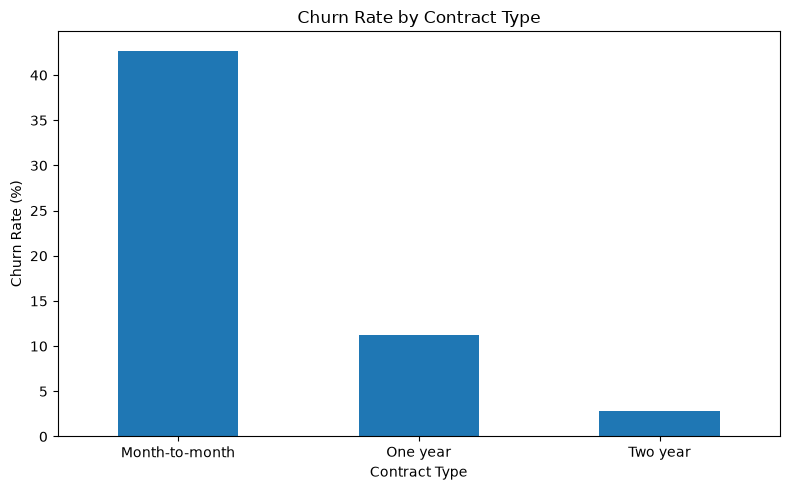

In [22]:
#Create a chart

contract_churn["churn_rate"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Churn Rate by Contract Type",
    ylabel="Churn Rate (%)",
    xlabel="Contract Type",
    rot=0
)
plt.tight_layout()
plt.show()

In [24]:
#Analyze churn by paymnet method

payment_churn = df.groupby("PaymentMethod").agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

payment_churn["Churn_Rate"] = (
    payment_churn["Churned_Customers"] /
    payment_churn["Total_Customers"]
) * 100

print(payment_churn.round(2))

                           Total_Customers  Churned_Customers  Churn_Rate
PaymentMethod                                                            
Bank transfer (automatic)             1544                258       16.71
Credit card (automatic)               1522                232       15.24
Electronic check                      2365               1071       45.29
Mailed check                          1612                308       19.11


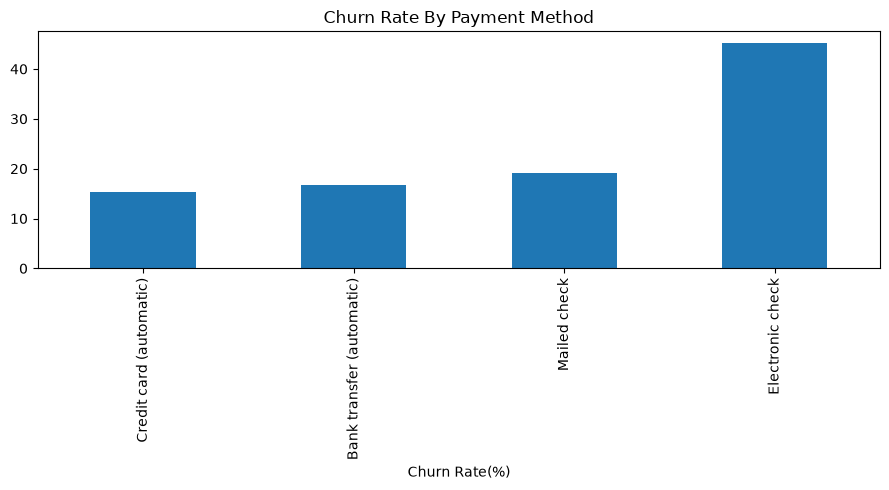

In [25]:
#Create Visulaization

payment_churn["Churn_Rate"].sort_values().plot(
    kind="bar",
    figsize=(9,5),
    title="Churn Rate By Payment Method",
    xlabel="Churn Rate(%)"
)

plt.tight_layout()
plt.show()

In [26]:
#Create tenure chorts
bins = [-1, 12, 24, 36, 48, 60, 72]

labels = [
    "0-12 Months",
    "13-24 Months",
    "25-36 Months",
    "37-48 Months",
    "49-60 Months",
    "61-72 Months"
]

df["TenureCohort"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels
)

print(df[["customerID", "tenure", "TenureCohort"]].head(10))

   customerID  tenure  TenureCohort
0  7590-VHVEG       1   0-12 Months
1  5575-GNVDE      34  25-36 Months
2  3668-QPYBK       2   0-12 Months
3  7795-CFOCW      45  37-48 Months
4  9237-HQITU       2   0-12 Months
5  9305-CDSKC       8   0-12 Months
6  1452-KIOVK      22  13-24 Months
7  6713-OKOMC      10   0-12 Months
8  7892-POOKP      28  25-36 Months
9  6388-TABGU      62  61-72 Months


In [27]:
#calucalte cohort churn

cohort_analysis = df.groupby(
    "TenureCohort",
    observed=False
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

cohort_analysis["Churn_Rate"] = (
    cohort_analysis["Churned_Customers"] /
    cohort_analysis["Total_Customers"]
) * 100

cohort_analysis["Retention_Rate"] = (
    100 - cohort_analysis["Churn_Rate"]
)

print(cohort_analysis.round(2))

              Total_Customers  Churned_Customers  Churn_Rate  Retention_Rate
TenureCohort                                                                
0-12 Months              2186               1037       47.44           52.56
13-24 Months             1024                294       28.71           71.29
25-36 Months              832                180       21.63           78.37
37-48 Months              762                145       19.03           80.97
49-60 Months              832                120       14.42           85.58
61-72 Months             1407                 93        6.61           93.39


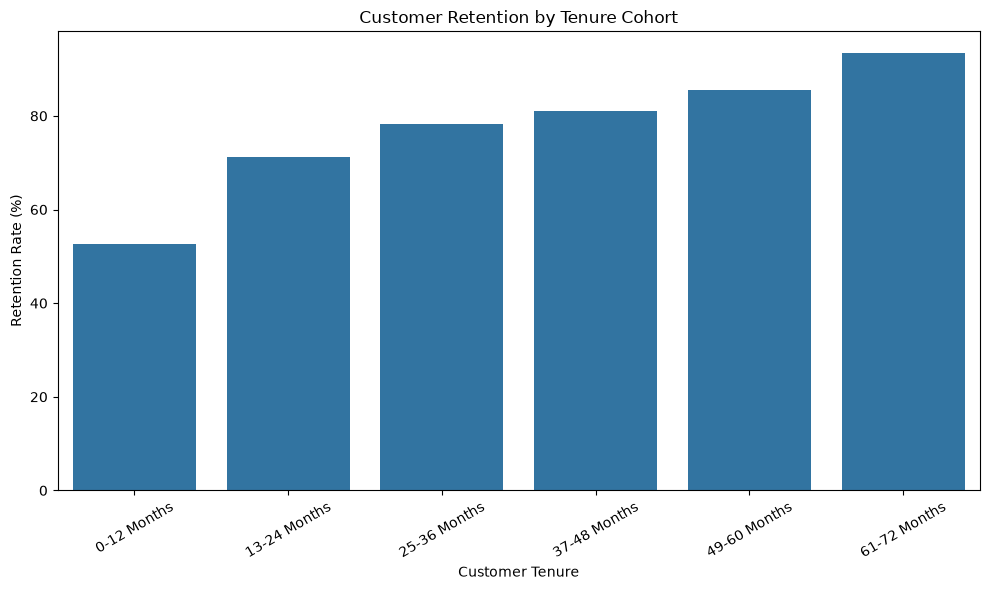

In [29]:
#Visualize cohort retention

plt.figure(figsize=(10, 6))

sns.barplot(
    x=cohort_analysis.index.astype(str),
    y=cohort_analysis["Retention_Rate"]
)

plt.title("Customer Retention by Tenure Cohort")
plt.xlabel("Customer Tenure")
plt.ylabel("Retention Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
output_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(output_dir / "cohort_retention.png", dpi=300)
plt.show()

In [30]:
#  Churn by Internet Service and Technical Support

risk_analysis = df.groupby(
    ["InternetService", "TechSupport"]
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

risk_analysis["Churn_Rate"] = (
    risk_analysis["Churned_Customers"] /
    risk_analysis["Total_Customers"]
) * 100

print(risk_analysis.sort_values(
    "Churn_Rate",
    ascending=False
).round(2))

                                     Total_Customers  Churned_Customers  \
InternetService TechSupport                                               
Fiber optic     No                              2230               1101   
DSL             No                              1243                345   
Fiber optic     Yes                              866                196   
DSL             Yes                             1178                114   
No              No internet service             1526                113   

                                     Churn_Rate  
InternetService TechSupport                      
Fiber optic     No                        49.37  
DSL             No                        27.76  
Fiber optic     Yes                       22.63  
DSL             Yes                        9.68  
No              No internet service        7.40  


In [31]:
#Analyze monthly charges
df["ChargeGroup"] = pd.qcut(
    df["MonthlyCharges"],
    q=4,
    duplicates="drop"
)

charge_analysis = df.groupby(
    "ChargeGroup",
    observed=False
).agg(
    Customers=("customerID", "count"),
    Churn_Rate=(
        "Churn",
        lambda x: (x == "Yes").mean() * 100
    )
)

print(charge_analysis.round(2))

                 Customers  Churn_Rate
ChargeGroup                           
(18.249, 35.5]        1762       11.24
(35.5, 70.35]         1766       24.58
(70.35, 89.85]        1757       37.51
(89.85, 118.75]       1758       32.88


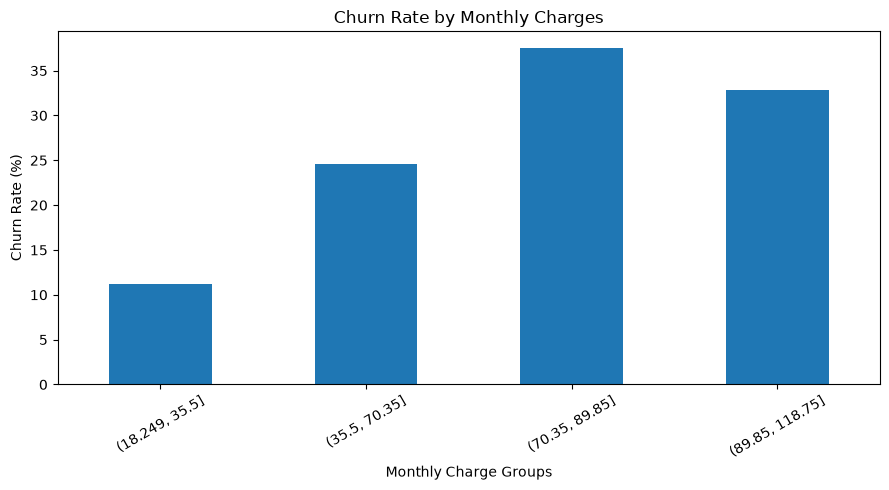

In [32]:
#Create a chart:

charge_analysis["Churn_Rate"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Churn Rate by Monthly Charges",
    ylabel="Churn Rate (%)",
    xlabel="Monthly Charge Groups",
    rot=30
)

plt.tight_layout()
plt.show()

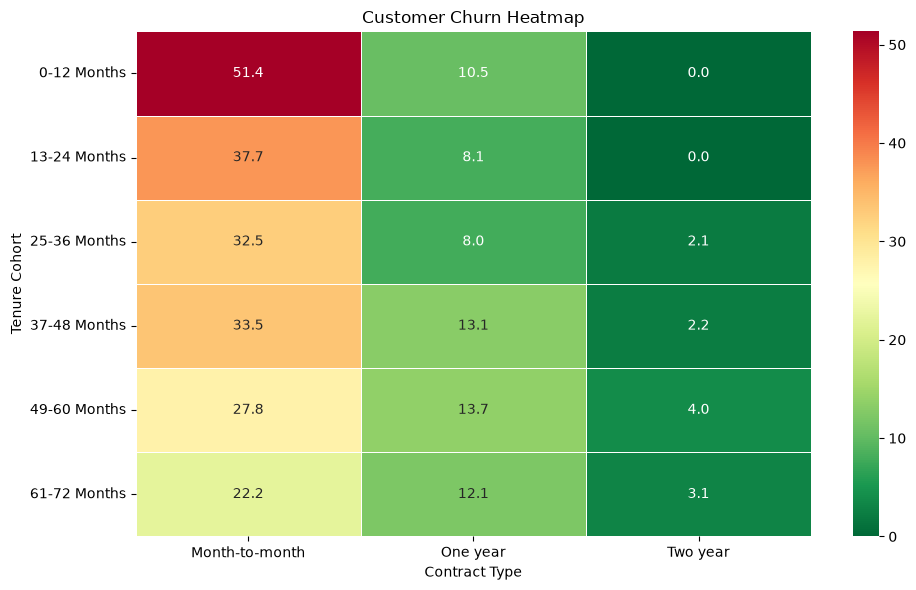

In [34]:
#Create a churn heatmap
heatmap_data = df.pivot_table(
    index="TenureCohort",
    columns="Contract",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100,
    observed=False
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Customer Churn Heatmap")
plt.xlabel("Contract Type")
plt.ylabel("Tenure Cohort")

plt.tight_layout()

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(output_dir / "churn_heatmap.png", dpi=300)

plt.show()

In [36]:
from pathlib import Path

#Export your analysis results
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

cohort_analysis.to_csv(
    output_dir / "cohort_retention.csv"
)

contract_churn.to_csv(
    "outputs/contract_churn.csv"
)

payment_churn.to_csv(
    "outputs/payment_churn.csv"
)

risk_analysis.to_csv(
    "outputs/high_risk_segments.csv"
)

charge_analysis.to_csv(
    "outputs/monthly_charge_analysis.csv"
)

print("All analysis files exported successfully!")

All analysis files exported successfully!
